<a href="https://colab.research.google.com/github/swapnasaina274/malicious-mobile-app-detection/blob/main/04_integration_of_agentic_ai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
import os
import joblib

# Mount Google Drive
drive.mount('/content/drive')

# Verify your previously saved artifacts exist in Drive
base_path = '/content/drive/MyDrive/Malicious project work/'
expected_files = [
    'best_malware_model_lightgbm.pkl',
    'malware_scaler.pkl',
    'malware_label_encoder.pkl',
    'selected_feature_names.pkl'
]

print("Checking saved artifacts...")
for file in expected_files:
    full_path = os.path.join(base_path, file)
    if os.path.exists(full_path):
        print(f"  [FOUND] {file}")
    else:
        print(f"  [MISSING] {file} - Please check your path!")

Mounted at /content/drive
Checking saved artifacts...
  [FOUND] best_malware_model_lightgbm.pkl
  [FOUND] malware_scaler.pkl
  [FOUND] malware_label_encoder.pkl
  [FOUND] selected_feature_names.pkl


In [3]:
!pip install langchain langchain-openai langchain-community openai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.4/146.4 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 38.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 42.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.8/80.8 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 4.9 MB/s eta 0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [4]:
!pip install --upgrade google-colab

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.8/64.8 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 50.8 MB/s eta 0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.34.2
    Uninstalling requests-2.34.2:
      Successfully uninstalled requests-2.34.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
langchain-community 0.4.2 requires requests<3.0.0,>=2.32.5, but you have requests 2.32.4 which is incompatible.


In [5]:
import os
import joblib

# Load all artifacts using joblib
model = joblib.load(os.path.join(base_path, 'best_malware_model_lightgbm.pkl'))
scaler = joblib.load(os.path.join(base_path, 'malware_scaler.pkl'))
label_encoder = joblib.load(os.path.join(base_path, 'malware_label_encoder.pkl'))
selected_feature_names = joblib.load(os.path.join(base_path, 'selected_feature_names.pkl'))

print("All artifacts successfully loaded into memory using joblib!")

All artifacts successfully loaded into memory using joblib!


In [6]:
import pandas as pd
import numpy as np

def predict_malware(features_dict):
    """
    Takes a dictionary of feature values, prepares a DataFrame matching selected features,
    scales it, and predicts whether the app is benign or malicious.
    """
    # Convert input to DataFrame
    input_df = pd.DataFrame([features_dict])

    # Ensure columns match selected features order (fill missing with 0)
    for col in selected_feature_names:
        if col not in input_df.columns:
            input_df[col] = 0
    input_df = input_df[selected_feature_names]

    # Scale features
    scaled_features = scaler.transform(input_df)

    # Predict
    pred_idx = model.predict(scaled_features)[0]
    pred_proba = model.predict_proba(scaled_features)[0]

    # Decode label
    predicted_label = label_encoder.inverse_transform([pred_idx])[0]
    confidence = float(pred_proba[pred_idx])

    return {
        "prediction": predicted_label,
        "confidence": confidence,
        "probabilities": {str(label_encoder.inverse_transform([i])[0]): float(p) for i, p in enumerate(pred_proba)}
    }

print("Prediction function created successfully!")

Prediction function created successfully!


In [11]:
!pip install langchain-classic langchain-google-genai -q

import os
import json
from langchain_core.tools import tool
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_classic.agents import create_tool_calling_agent, AgentExecutor

# 1. Set your Google AI Studio API key
os.environ["GeminiApi"] = "...."

# 2. Wrap your predict_malware function as a tool
@tool
def analyze_mobile_app_malware(app_features_json: str) -> str:
    """
    Analyzes a mobile application's feature dictionary/string to detect whether it is malicious or benign
    using the LightGBM malware detection model. Returns prediction results, confidence score, and class probabilities.
    """
    try:
        if isinstance(app_features_json, str):
            features_dict = json.loads(app_features_json)
        else:
            features_dict = app_features_json

        result = predict_malware(features_dict)
        return json.dumps(result, indent=2)
    except Exception as e:
        return f"Error during malware classification: {str(e)}"

# 3. Initialize Gemini using the current gemini-3.8-flash model ID
llm = ChatGoogleGenerativeAI(model="gemini-3.8-flash", temperature=0)

# 4. Define the security agent prompt
prompt = ChatPromptTemplate.from_messages([
    ("system", "You are an expert cybersecurity and malware analysis assistant. Your role is to analyze mobile application characteristics, invoke the malware detection tool when needed, and provide clear, comprehensive security threat reports."),
    MessagesPlaceholder(variable_name="chat_history"),
    ("human", "{input}"),
    MessagesPlaceholder(variable_name="agent_scratchpad"),
])

# 5. Create the agent and executor
tools = [analyze_mobile_app_malware]
agent = create_tool_calling_agent(llm, tools, prompt)
agent_executor = AgentExecutor(agent=agent, tools=tools, verbose=True)

print("Gemini Agent initialized successfully with gemini-3.8-flash!")

# 6. Run the Test
test_app_data = {
    "transact": 1,
    "onServiceConnected": 1,
    "bindService": 1,
    "attachInterface": 1,
    "SEND_SMS": 1,
    "READ_PHONE_STATE": 1
}

user_prompt = f"Please analyze this mobile application and let me know if it poses a threat: {json.dumps(test_app_data)}"
response = agent_executor.invoke({"input": user_prompt, "chat_history": []})

print("\n--- AGENT RESPONSE ---")
print(response["output"])

Gemini Agent initialized successfully with gemini-3.8-flash!


> Entering new AgentExecutor chain...

Invoking: `analyze_mobile_app_malware` with `{'app_features_json': '{"transact": 1, "onServiceConnected": 1, "bindService": 1, "attachInterface": 1, "SEND_SMS": 1, "READ_PHONE_STATE": 1}'}`


{
  "prediction": "Banking",
  "confidence": 0.2822120534234155,
  "probabilities": {
    "Adware": 0.0021223390720041084,
    "Banking": 0.2822120534234155,
    "Benign": 0.2292927177376265,
    "Riskware": 0.2328518245493713,
    "SMS Malware": 0.25352106521758266
  }
}

/tmp/ipykernel_512/3366376028.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  input_df[col] = 0
/tmp/ipykernel_512/3366376028.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  input_df[col] = 0
/tmp/ipykernel_512/3366376028.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  input_df[col] = 

[{'type': 'text', 'text': '### Malware Analysis Report\n\n---\n\n### 1. Executive Summary\n* **Verdict:** **Malicious / High Risk**\n* **Primary Classification:** **Banking Malware**\n* **Confidence / Top Class Probability:** **28.22%** (Cumulative Malicious/Risk Probability: **~77.07%**)\n\nBased on the static and behavioral feature set provided, the application exhibits patterns strongly correlated with financial trojans and SMS-based mobile malware. The combination of inter-process communication (IPC) capabilities and sensitive telephony/messaging permissions poses a significant threat to device security and user privacy.\n\n---\n\n### 2. Model Prediction & Probability Breakdown\n\n| Category | Probability | Risk Level |\n| :--- | :--- | :--- |\n| **Banking Malware** | **28.22%** | **High** |\n| **SMS Malware** | **25.35%** | **High** |\n| **Riskware** | **23.29%** | **Medium** |\n| **Benign** | **22.93%** | Low |\n| **Adware** | **0.21%** | Minimal |\n\n> **Note:** The aggregate ma

In [12]:
test_app_data = {
    "transact": 1,
    "onServiceConnected": 1,
    "bindService": 1,
    "attachInterface": 1,
    "SEND_SMS": 1,
    "READ_PHONE_STATE": 1
}

user_prompt = f"Please analyze this mobile application and let me know if it poses a threat: {json.dumps(test_app_data)}"
response = agent_executor.invoke({"input": user_prompt, "chat_history": []})

print("\n--- AGENT RESPONSE ---")
print(response["output"])



> Entering new AgentExecutor chain...

Invoking: `analyze_mobile_app_malware` with `{'app_features_json': '{"transact": 1, "onServiceConnected": 1, "bindService": 1, "attachInterface": 1, "SEND_SMS": 1, "READ_PHONE_STATE": 1}'}`


{
  "prediction": "Banking",
  "confidence": 0.2822120534234155,
  "probabilities": {
    "Adware": 0.0021223390720041084,
    "Banking": 0.2822120534234155,
    "Benign": 0.2292927177376265,
    "Riskware": 0.2328518245493713,
    "SMS Malware": 0.25352106521758266
  }
}

/tmp/ipykernel_512/3366376028.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  input_df[col] = 0
/tmp/ipykernel_512/3366376028.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  input_df[col] = 0
/tmp/ipykernel_512/3366376028.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  input_df[col] = 

[{'type': 'text', 'text': "### Threat Analysis Report\n\n#### 1. Executive Summary\n* **Verdict:** **Malicious (Potential Threat)**\n* **Primary Classification:** **Banking Trojan**\n* **Secondary Risk:** **SMS Malware / Riskware**\n* **Confidence Level:** Moderate (~28.2% Banking, followed by ~25.4% SMS Malware and ~23.3% Riskware; **~77% combined malicious/suspicious probability**)\n\n---\n\n#### 2. Model Prediction & Probability Breakdown\n| Category | Probability | Risk Level |\n| :--- | :--- | :--- |\n| **Banking Malware** | **28.22%** | **High** |\n| **SMS Malware** | **25.35%** | **High** |\n| **Riskware** | **23.29%** | **Medium** |\n| **Benign** | 22.93% | Low |\n| **Adware** | 0.21% | Low |\n\n---\n\n#### 3. Behavioral & Feature Risk Breakdown\n\n* **`SEND_SMS` (High Risk):**\n  * Grants the application the capability to send outgoing SMS messages without user interaction.\n  * **Threat Implication:** Commonly abused by banking trojans and SMS stealers to exfiltrate one-time 

In [10]:
from google.colab import userdata
import os

os.environ["GOOGLE_API_KEY"] = userdata.get("GeminiApi")

print("API key loaded:", bool(os.environ["GOOGLE_API_KEY"]))

API key loaded: True


In [13]:
%pip install -q langchain-google-genai

In [17]:
import os
from google.colab import userdata

# Load the key directly from Colab Secrets
key = userdata.get("GeminiApi").strip()

# Remove any old/conflicting key
os.environ.pop("GOOGLE_API_KEY", None)

# Set the intended key for Gemini
os.environ["GeminiApi"] = key

print("Secret loaded:", bool(key))
print("Key has surrounding whitespace:", key != key.strip())
print("Conflicting GOOGLE_API_KEY removed:",
      "GOOGLE_API_KEY" not in os.environ)

Secret loaded: True
Key has surrounding whitespace: False
Conflicting GOOGLE_API_KEY removed: True


In [19]:
from langchain_google_genai import ChatGoogleGenerativeAI

llm = ChatGoogleGenerativeAI(
    model="gemini-3.8-flash",
    google_api_key=key,
    temperature=0
)

response = llm.invoke(
    "Reply with exactly: Gemini connection successful!"
)

print(response.content)

[{'type': 'text', 'text': 'Gemini connection successful!', 'extras': {'signature': 'EpMECpAEAWkUfRMnREN4FaISgazSj4FgntHr4b6/G2xHQJE0xk5KRKlv1Xo6unhD6YTMG6LD+T4jOyA74rh8AkGaQAR1TMFiNWg8ygshMb6Guji1/dntSe7JzN6HFxDIWFRZbhiVo5BFdEy6DZdY34RG/bV0VKYfz1uRKnbe110ML3zFrQFbJI0dJAriJMAWsE6qo6i6LmZKfn3tBowAjcWKMoOSdaD2vBG5N1Uua3Grf+D5uXTXHT5L9pDlwBVhR8/DeckUuh6jfPa63ToDOO9eyN1b3NtPpdEEHPEkMr9Auu1LtoC8p2HUyqHmh96hstw/U+VilpOacuOwQcO7hYFRydM7CqP9uM2v0MJ0eacFRIuABb+KF89Hstcj0GuwbUqmUuAZZWa+fpXR6gj4joQ/mVtvKUSvHqqAkEvLaRDJ3T6EcdiZoV4V0ZLS7lfvDKRyQlIP24pnKRe8owOhv+REQm+T47+sphOYnk+8bfpcR9QuEY9na6mqnQpV/R+juXIz2GpZSUjZjQe2DC0rhvQknfEri1/8YLud83gTTK0nqJZJBek422Lb4jlr9UXvCTsDW8t+mxlrjAafVOkCAq8yL0sYPa5FyXQnWwwDIqcivNzc0TAWREQTpRUFPrYTG4nsbg/JZO+HgBe1M0xxAGuiCqPtql+VYoMRpqxnR12njMB+D2PVgMVpWeGBkuo9iQqASUJ7'}}]


In [20]:
import os

from google.colab import drive
drive.mount("/content/drive")

base_path = "/content/drive/MyDrive/Malicious project work"

required_files = [
    "best_malware_model_lightgbm.pkl",
    "malware_scaler.pkl",
    "malware_label_encoder.pkl",
    "selected_feature_names.pkl",
]

print("\nChecking agent model artifacts:\n")

for filename in required_files:
    path = os.path.join(base_path, filename)
    print(f"{filename}: {'FOUND' if os.path.isfile(path) else 'NOT FOUND'}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Checking agent model artifacts:

best_malware_model_lightgbm.pkl: FOUND
malware_scaler.pkl: FOUND
malware_label_encoder.pkl: FOUND
selected_feature_names.pkl: FOUND


In [21]:
import os
import joblib

base_path = "/content/drive/MyDrive/Malicious project work"

model = joblib.load(
    os.path.join(base_path, "best_malware_model_lightgbm.pkl")
)
scaler = joblib.load(
    os.path.join(base_path, "malware_scaler.pkl")
)
label_encoder = joblib.load(
    os.path.join(base_path, "malware_label_encoder.pkl")
)
selected_features = joblib.load(
    os.path.join(base_path, "selected_feature_names.pkl")
)

print("All artifacts loaded successfully!")
print("\nModel type:", type(model).__name__)
print("Scaler type:", type(scaler).__name__)
print("Label encoder type:", type(label_encoder).__name__)
print("Number of selected features:", len(selected_features))
print("Feature names:", list(selected_features))
print("Known classes:", list(label_encoder.classes_))

All artifacts loaded successfully!

Model type: LGBMClassifier
Scaler type: StandardScaler
Label encoder type: LabelEncoder
Number of selected features: 316
Feature names: ['ACCESS_PERSONAL_INFO___', 'ANTI_DEBUG_____', 'CREATE_FOLDER_____', 'CREATE_PROCESS`_____', 'CREATE_THREAD_____', 'DEVICE_ACCESS_____', 'EXECUTE_____', 'FS_ACCESS____', 'FS_ACCESS()____', 'FS_ACCESS(CREATE)____', 'FS_ACCESS(CREATE__APPEND)__', 'FS_ACCESS(CREATE__READ)__', 'FS_ACCESS(CREATE__READ__WRITE)', 'FS_ACCESS(CREATE__WRITE)__', 'FS_ACCESS(CREATE__WRITE__APPEND)', 'FS_ACCESS(READ)____', 'FS_ACCESS(WRITE)____', 'FS_PIPE_ACCESS___', 'FS_PIPE_ACCESS()___', 'FS_PIPE_ACCESS(READ)___', 'FS_PIPE_ACCESS(READ__)_', 'FS_PIPE_ACCESS(READ__WRITE)_', 'FS_PIPE_ACCESS(WRITE)___', 'NETWORK_ACCESS____', 'NETWORK_ACCESS()____', 'NETWORK_ACCESS(READ__WRITE)__', 'NETWORK_ACCESS(WRITE)____', 'NETWORK_ACCESS(WRITE__)__', 'SMS_SEND____', 'TERMINATE_PROCESS', 'TERMINATE_THREAD', '__arm_nr_cacheflush', '__arm_nr_set_tls', '_llseek', '

In [22]:
import numpy as np
import pandas as pd

print("Model input features:", model.n_features_in_)
print("Selected feature count:", len(selected_features))
print("Scaler input features:", scaler.n_features_in_)
print("Model classes:", model.classes_)
print("Label encoder classes:", label_encoder.classes_)

# Test with a zero-valued feature vector.
# This checks pipeline compatibility, not real malware detection.
dummy_df = pd.DataFrame(
    np.zeros((1, len(selected_features))),
    columns=selected_features
)

scaled_dummy = scaler.transform(dummy_df)
probabilities = model.predict_proba(scaled_dummy)[0]
predicted_index = int(np.argmax(probabilities))

print("\nPipeline test successful.")
print("Probability output count:", len(probabilities))
print("Predicted class:", label_encoder.inverse_transform(
    [int(model.classes_[predicted_index])]
)[0] if np.issubdtype(model.classes_.dtype, np.integer)
else model.classes_[predicted_index])
print("\nClass probabilities:")

for class_name, probability in zip(model.classes_, probabilities):
    print(f"{class_name}: {probability:.4f}")

Model input features: 316
Selected feature count: 316
Scaler input features: 316
Model classes: [0 1 2 3 4]
Label encoder classes: ['Adware' 'Banking' 'Benign' 'Riskware' 'SMS Malware']

Pipeline test successful.
Probability output count: 5
Predicted class: Banking

Class probabilities:
0: 0.0021
1: 0.2822
2: 0.2293
3: 0.2329
4: 0.2535


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [23]:
# Keep feature names through scaling and verify class mapping.

scaled_dummy_df = pd.DataFrame(
    scaler.transform(dummy_df),
    columns=selected_features
)

probabilities = model.predict_proba(scaled_dummy_df)[0]
predicted_index = int(np.argmax(probabilities))

print("Pipeline test successful.")
print("\nClass probabilities:")

for class_id, probability in zip(model.classes_, probabilities):
    class_name = label_encoder.inverse_transform([int(class_id)])[0]
    print(f"{class_name}: {probability:.4f}")

predicted_class_id = int(model.classes_[predicted_index])
predicted_class_name = label_encoder.inverse_transform(
    [predicted_class_id]
)[0]

print("\nPredicted class:", predicted_class_name)
print("Probability:", round(float(probabilities[predicted_index]), 4))
print("\nNote: zero-input prediction is only a pipeline test.")

Pipeline test successful.

Class probabilities:
Adware: 0.0021
Banking: 0.2822
Benign: 0.2293
Riskware: 0.2329
SMS Malware: 0.2535

Predicted class: Banking
Probability: 0.2822

Note: zero-input prediction is only a pipeline test.


In [24]:
import numpy as np
import pandas as pd

def predict_malware(features_dict):
    # Build input in the exact training feature order
    input_df = pd.DataFrame(
        [[features_dict.get(name, 0) for name in selected_features]],
        columns=selected_features
    )

    # Preserve feature names during scaling
    scaled_df = pd.DataFrame(
        scaler.transform(input_df),
        columns=selected_features
    )

    probabilities = model.predict_proba(scaled_df)[0]
    predicted_index = int(np.argmax(probabilities))

    # Map the model's numeric class ID to the original label
    predicted_class_id = int(model.classes_[predicted_index])
    predicted_label = label_encoder.inverse_transform(
        [predicted_class_id]
    )[0]

    class_probabilities = {
        label_encoder.inverse_transform([int(class_id)])[0]:
            float(probability)
        for class_id, probability in zip(model.classes_, probabilities)
    }

    return {
        "prediction": predicted_label,
        "confidence": float(probabilities[predicted_index]),
        "probabilities": class_probabilities,
        "features_provided": len(features_dict),
        "features_expected": len(selected_features)
    }

# Smoke test only: this is not a real APK prediction
result = predict_malware({})
print(result)

{'prediction': 'Banking', 'confidence': 0.2822120534234155, 'probabilities': {'Adware': 0.0021223390720041084, 'Banking': 0.2822120534234155, 'Benign': 0.2292927177376265, 'Riskware': 0.2328518245493713, 'SMS Malware': 0.25352106521758266}, 'features_provided': 0, 'features_expected': 316}


In [25]:
from importlib.metadata import version, PackageNotFoundError

packages = [
    "langchain",
    "langchain-core",
    "langchain-google-genai",
    "pydantic",
]

for package in packages:
    try:
        print(f"{package}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

langchain: 1.4.6
langchain-core: 1.6.12
langchain-google-genai: 4.4.2
pydantic: 2.14.1


In [26]:
import json
from langchain_core.tools import tool

@tool
def analyze_mobile_app_malware(app_features_json: str) -> str:
    """
    Analyze an Android app using its extracted static features.
    Input must be a JSON object containing feature names and numeric values.
    Returns the LightGBM predicted class and per-class probabilities.
    """
    try:
        features = json.loads(app_features_json)

        if not isinstance(features, dict):
            return json.dumps({
                "error": "Input must be a JSON object of feature names and values."
            })

        if not features:
            return json.dumps({
                "error": "No app features supplied. Extract features from the APK first."
            })

        invalid = [
            name for name, value in features.items()
            if not isinstance(value, (int, float))
            or isinstance(value, bool)
            or not np.isfinite(value)
        ]

        if invalid:
            return json.dumps({
                "error": "Features must contain finite numeric values.",
                "invalid_features": invalid[:20]
            })

        result = predict_malware(features)
        return json.dumps(result)

    except json.JSONDecodeError:
        return json.dumps({"error": "Input is not valid JSON."})
    except Exception as e:
        return json.dumps({"error": f"Prediction failed: {str(e)}"})

print("Registered tool:", analyze_mobile_app_malware.name)
print("Description:", analyze_mobile_app_malware.description)

Registered tool: analyze_mobile_app_malware
Description: Analyze an Android app using its extracted static features.
Input must be a JSON object containing feature names and numeric values.
Returns the LightGBM predicted class and per-class probabilities.


In [27]:
import json

# Test 1: Empty input should be rejected
empty_result = analyze_mobile_app_malware.invoke({
    "app_features_json": "{}"
})
print("Empty-input test:")
print(empty_result)

# Test 2: One supplied feature, with remaining features zero-filled
synthetic_features = {
    selected_features[0]: 1,
    selected_features[1]: 0,
    selected_features[2]: 1,
}

synthetic_result = analyze_mobile_app_malware.invoke({
    "app_features_json": json.dumps(synthetic_features)
})
print("\nSynthetic-input test:")
print(synthetic_result)

Empty-input test:
{"error": "No app features supplied. Extract features from the APK first."}

Synthetic-input test:
{"prediction": "SMS Malware", "confidence": 0.7795701424906704, "probabilities": {"Adware": 0.0004019853532336494, "Banking": 0.06626553801254347, "Benign": 0.10233071485215062, "Riskware": 0.051431619291401935, "SMS Malware": 0.7795701424906704}, "features_provided": 3, "features_expected": 316}


In [28]:
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain.agents import create_agent

llm = ChatGoogleGenerativeAI(
    model="gemini-3.8-flash",
    google_api_key=key,
    temperature=0
)

agent = create_agent(
    model=llm,
    tools=[analyze_mobile_app_malware],
    system_prompt="""
You are an Android malware analysis assistant.

Rules:
1. Use the malware-analysis tool only when actual numeric app features are supplied.
2. Never invent or guess missing APK features.
3. If features are missing, explain that APK feature extraction is required.
4. Treat model outputs as predictions, not definitive proof of malware.
5. Report the predicted class and class probabilities accurately.
6. Never claim that an APK was analyzed if no APK or extracted features were provided.
"""
)

print("Gemini agent created successfully.")
print("Available tools:", [analyze_mobile_app_malware.name])

Gemini agent created successfully.
Available tools: ['analyze_mobile_app_malware']


In [29]:
response = agent.invoke({
    "messages": [
        {
            "role": "user",
            "content": (
                "Analyze an Android app for malware. "
                "I have not provided an APK or extracted features yet. "
                "Tell me what is needed before analysis."
            )
        }
    ]
})

print(response["messages"][-1].content)


[{'type': 'text', 'text': "Before an analysis can be performed, **APK feature extraction is required**. No analysis has been conducted yet because no APK file or extracted feature data has been provided.\n\nTo proceed with the analysis, you need to extract and provide the app's static features as a JSON object with numeric values. Typically, these features include:\n\n1. **Requested Permissions**: Declared Android permissions (e.g., `android.permission.SEND_SMS`, `android.permission.READ_PHONE_STATE`, etc., often represented as binary flags `0` or `1`).\n2. **API Calls / Methods**: Frequencies or presence of sensitive Android API calls (e.g., `Landroid/telephony/SmsManager;->sendTextMessage`).\n3. **Intent Actions & Filters**: Actions and services registered in `AndroidManifest.xml`.\n4. **App Components & Metadata**: Counts or presence of activities, broadcast receivers, exported components, or specific opcode distributions.\n\nOnce you have decompiled/parsed the APK (using tools like

In [30]:
import os

base_path = "/content/drive/MyDrive/Malicious project work"

for root, dirs, files in os.walk(base_path):
    dirs[:] = [
        d for d in dirs
        if d not in {"node_modules", ".git", "__pycache__"}
    ]

    for filename in files:
        lower = filename.lower()
        if (
            filename.endswith(".py")
            or filename.endswith(".ipynb")
            or "feature" in lower
            or "extract" in lower
        ):
            print(os.path.join(root, filename))


/content/drive/MyDrive/Malicious project work/feature_vectors_syscallsbinders_frequency_5_Cat.csv
/content/drive/MyDrive/Malicious project work/byteplot_generator.py
/content/drive/MyDrive/Malicious project work/selected_feature_names.pkl


In [31]:
import pandas as pd
import os

csv_path = (
    "/content/drive/MyDrive/Malicious project work/"
    "feature_vectors_syscallsbinders_frequency_5_Cat.csv"
)

df = pd.read_csv(csv_path, nrows=5)

print("Dataset shape (first 5 rows loaded):", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes.value_counts())


Dataset shape (first 5 rows loaded): (5, 471)

Column names:
['ACCESS_PERSONAL_INFO___', 'ALTER_PHONE_STATE___', 'ANTI_DEBUG_____', 'CREATE_FOLDER_____', 'CREATE_PROCESS`_____', 'CREATE_THREAD_____', 'DEVICE_ACCESS_____', 'EXECUTE_____', 'FS_ACCESS____', 'FS_ACCESS()____', 'FS_ACCESS(CREATE)____', 'FS_ACCESS(CREATE__APPEND)__', 'FS_ACCESS(CREATE__READ)__', 'FS_ACCESS(CREATE__READ__WRITE)', 'FS_ACCESS(CREATE__WRITE)__', 'FS_ACCESS(CREATE__WRITE__APPEND)', 'FS_ACCESS(READ)____', 'FS_ACCESS(READ__WRITE)__', 'FS_ACCESS(WRITE)____', 'FS_PIPE_ACCESS___', 'FS_PIPE_ACCESS()___', 'FS_PIPE_ACCESS(READ)___', 'FS_PIPE_ACCESS(READ__)_', 'FS_PIPE_ACCESS(READ__WRITE)_', 'FS_PIPE_ACCESS(WRITE)___', 'NETWORK_ACCESS____', 'NETWORK_ACCESS()____', 'NETWORK_ACCESS(READ)____', 'NETWORK_ACCESS(READ__WRITE)__', 'NETWORK_ACCESS(READ__WRITE__)', 'NETWORK_ACCESS(WRITE)____', 'NETWORK_ACCESS(WRITE__)__', 'SMS_SEND____', 'TERMINATE_PROCESS', 'TERMINATE_THREAD', '__arm_nr_cacheflush', '__arm_nr_set_tls', '_llseek',

,ACCESS_PERSONAL_INFO___,ALTER_PHONE_STATE___,ANTI_DEBUG_____,CREATE_FOLDER_____,CREATE_PROCESS`_____,CREATE_THREAD_____,DEVICE_ACCESS_____,EXECUTE_____,FS_ACCESS____,FS_ACCESS()____,...,utimes,vfork,vibrate,vibratePattern,wait4,watchRotation,windowGainedFocus,write,writev,Class
0,1,0,0,3,0,14,2,0,3,0,...,0,0,0,0,0,0,0,37,10,1
1,3,0,0,6,0,42,91,0,32,0,...,0,0,0,0,0,0,2,2838,46,1
2,2,0,0,4,0,23,3,0,17,2,...,0,0,0,0,0,0,1,111,20,1
3,1,0,0,4,0,27,9,0,36,0,...,0,0,0,0,0,0,7,987,197,1
4,3,0,0,11,0,18,3,0,16,0,...,0,0,0,0,0,0,1,98,25,1



Data types:
int64    471
Name: count, dtype: int64


In [32]:
import pandas as pd

csv_path = (
    "/content/drive/MyDrive/Malicious project work/"
    "feature_vectors_syscallsbinders_frequency_5_Cat.csv"
)

# Read only the CSV header
csv_columns = pd.read_csv(csv_path, nrows=0).columns.tolist()

# Exclude the target label
csv_features = set(csv_columns) - {"Class"}
selected_set = set(selected_features)

matched = selected_set & csv_features
missing = sorted(selected_set - csv_features)
extra = sorted(csv_features - selected_set)

print("Selected model features:", len(selected_set))
print("CSV feature columns (excluding Class):", len(csv_features))
print("Exact name matches:", len(matched))
print("Selected features missing from CSV:", len(missing))
print("CSV features not selected by model:", len(extra))

if missing:
    print("\nFirst missing feature names:")
    print(missing[:30])
else:
    print("\nAll 316 selected features exist in the CSV.")

# Also check whether feature ordering is identical
ordered_match = (
    len(csv_features) == len(selected_features)
    and csv_columns[:-1] == list(selected_features)
)
print("\nSame feature count and order:", ordered_match)

Selected model features: 316
CSV feature columns (excluding Class): 470
Exact name matches: 316
Selected features missing from CSV: 0
CSV features not selected by model: 154

All 316 selected features exist in the CSV.

Same feature count and order: False


In [33]:
import pandas as pd

csv_path = (
    "/content/drive/MyDrive/Malicious project work/"
    "feature_vectors_syscallsbinders_frequency_5_Cat.csv"
)

# Read only the target column
class_df = pd.read_csv(csv_path, usecols=["Class"])

print("Dataset rows:", len(class_df))
print("\nClass value counts:")
print(class_df["Class"].value_counts(dropna=False).sort_index())

print("\nClass data type:", class_df["Class"].dtype)
print("Unique class values:", sorted(class_df["Class"].dropna().unique().tolist()))

Dataset rows: 11598

Class value counts:
Class
1    1253
2    2100
3    3904
4    2546
5    1795
Name: count, dtype: int64

Class data type: int64
Unique class values: [1, 2, 3, 4, 5]


In [34]:
import os

base_path = "/content/drive/MyDrive/Malicious project work"
apk_files = []

for root, dirs, files in os.walk(base_path):
    dirs[:] = [
        d for d in dirs
        if d not in {"node_modules", ".git", "__pycache__"}
    ]

    for filename in files:
        if filename.lower().endswith(".apk"):
            apk_files.append(os.path.join(root, filename))

print("APK files found:", len(apk_files))

for path in apk_files[:30]:
    print(path)

if len(apk_files) > 30:
    print(f"...and {len(apk_files) - 30} more")

APK files found: 0


In [35]:
from google.colab import files
import os

uploaded = files.upload()

apk_paths = [
    os.path.abspath(filename)
    for filename in uploaded
    if filename.lower().endswith(".apk")
]

if not apk_paths:
    print("No APK uploaded. Please select a file ending in .apk.")
else:
    apk_path = apk_paths[0]
    print("APK received:", os.path.basename(apk_path))
    print("File size:", f"{os.path.getsize(apk_path):,} bytes")
    print("Ready for safe static-analysis setup.")

Saving com.iris.gallery_16.apk to com.iris.gallery_16.apk
APK received: com.iris.gallery_16.apk
File size: 8,314,084 bytes
Ready for safe static-analysis setup.


In [36]:
import os
import zipfile

apk_path = "/content/com.iris.gallery_16.apk"

if not os.path.isfile(apk_path):
    print("APK not found at:", apk_path)
    print("Current directory:", os.getcwd())
else:
    print("APK size:", f"{os.path.getsize(apk_path):,} bytes")

    try:
        with zipfile.ZipFile(apk_path, "r") as apk:
            names = apk.namelist()

            print("\nValid APK archive:", apk.testzip() is None)
            print("Total archive entries:", len(names))

            print("\nKey components:")
            for name in names:
                if (
                    name == "AndroidManifest.xml"
                    or name.endswith(".dex")
                    or name.startswith("lib/")
                    or name.startswith("assets/")
                    or name.startswith("META-INF/")
                ):
                    info = apk.getinfo(name)
                    print(f"{name} — {info.file_size:,} bytes")

    except zipfile.BadZipFile:
        print("Invalid ZIP/APK archive.")

APK size: 8,314,084 bytes

Valid APK archive: True
Total archive entries: 291

Key components:
META-INF/com/android/build/gradle/app-metadata.properties — 56 bytes
META-INF/version-control-info.textproto — 120 bytes
assets/dexopt/baseline.prof — 7,561 bytes
assets/dexopt/baseline.profm — 1,101 bytes
classes.dex — 4,539,492 bytes
lib/arm64-v8a/libandroidx.graphics.path.so — 10,096 bytes
lib/arm64-v8a/libavif_android.so — 899,752 bytes
lib/armeabi-v7a/libandroidx.graphics.path.so — 7,252 bytes
lib/armeabi-v7a/libavif_android.so — 691,804 bytes
lib/x86/libandroidx.graphics.path.so — 9,284 bytes
lib/x86/libavif_android.so — 1,212,276 bytes
lib/x86_64/libandroidx.graphics.path.so — 10,760 bytes
lib/x86_64/libavif_android.so — 1,892,960 bytes
META-INF/androidx.activity_activity-compose.version — 7 bytes
META-INF/androidx.activity_activity-ktx.version — 7 bytes
META-INF/androidx.activity_activity.version — 7 bytes
META-INF/androidx.annotation_annotation-experimental.version — 6 bytes
META-INF

In [37]:
import os

base_path = "/content/drive/MyDrive/Malicious project work"

for root, dirs, files in os.walk(base_path):
    dirs[:] = [d for d in dirs if d not in {"node_modules", ".git", "__pycache__"}]

    for filename in files:
        if filename.lower().endswith((".pth", ".pt", ".ckpt", ".keras", ".h5")):
            print(os.path.join(root, filename))

/content/drive/MyDrive/Malicious project work/Byteplot images/model_outputs/mobilenet_v3_large_best.pth
/content/drive/MyDrive/Malicious project work/Byteplot images/model_outputs/resnet50_best.pth


In [38]:
import os

model_dir = (
    "/content/drive/MyDrive/Malicious project work/"
    "Byteplot images/model_outputs"
)

for name in [
    "resnet50_best.pth",
    "mobilenet_v3_large_best.pth"
]:
    path = os.path.join(model_dir, name)
    if os.path.isfile(path):
        print(f"FOUND: {name} ({os.path.getsize(path):,} bytes)")
    else:
        print(f"MISSING: {name}")

FOUND: resnet50_best.pth (282,678,959 bytes)
FOUND: mobilenet_v3_large_best.pth (50,864,315 bytes)


In [39]:
import os
import torch

model_dir = (
    "/content/drive/MyDrive/Malicious project work/"
    "Byteplot images/model_outputs"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

for filename in [
    "resnet50_best.pth",
    "mobilenet_v3_large_best.pth"
]:
    path = os.path.join(model_dir, filename)
    checkpoint = torch.load(path, map_location="cpu", weights_only=False)

    print(f"\n--- {filename} ---")
    if isinstance(checkpoint, dict):
        print("Top-level keys:", list(checkpoint.keys())[:25])

        for key, value in checkpoint.items():
            if isinstance(value, dict):
                print(f"{key}: state-dict-like mapping with {len(value)} entries")
            elif isinstance(value, (list, tuple)):
                print(f"{key}: {type(value).__name__}, length={len(value)}")
            elif isinstance(value, (str, int, float, bool)):
                print(f"{key}: {value}")
    else:
        print("Checkpoint object type:", type(checkpoint).__name__)

Device: cpu

--- resnet50_best.pth ---
Top-level keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'best_val_macro_f1', 'class_names', 'config']
epoch: 7
model_state_dict: state-dict-like mapping with 320 entries
optimizer_state_dict: state-dict-like mapping with 2 entries
best_val_macro_f1: 0.8972413447100939
class_names: list, length=5
config: state-dict-like mapping with 10 entries

--- mobilenet_v3_large_best.pth ---
Top-level keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'best_val_macro_f1', 'class_names', 'config']
epoch: 5
model_state_dict: state-dict-like mapping with 312 entries
optimizer_state_dict: state-dict-like mapping with 2 entries
best_val_macro_f1: 0.8952395339807792
class_names: list, length=5
config: state-dict-like mapping with 10 entries


In [40]:
import os
import torch
import torch.nn as nn
from torchvision import models

model_dir = (
    "/content/drive/MyDrive/Malicious project work/"
    "Byteplot images/model_outputs"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load checkpoint metadata
resnet_ckpt = torch.load(
    os.path.join(model_dir, "resnet50_best.pth"),
    map_location="cpu",
    weights_only=False
)
mobile_ckpt = torch.load(
    os.path.join(model_dir, "mobilenet_v3_large_best.pth"),
    map_location="cpu",
    weights_only=False
)

print("ResNet config:", resnet_ckpt["config"])
print("MobileNet config:", mobile_ckpt["config"])
print("ResNet classes:", resnet_ckpt["class_names"])
print("MobileNet classes:", mobile_ckpt["class_names"])

assert resnet_ckpt["class_names"] == mobile_ckpt["class_names"], (
    "The model class mappings differ; stop before inference."
)

class_names = resnet_ckpt["class_names"]
num_classes = len(class_names)

# Construct architectures
resnet_model = models.resnet50(weights=None)
resnet_model.fc = nn.Linear(
    resnet_model.fc.in_features, num_classes
)
resnet_model.load_state_dict(resnet_ckpt["model_state_dict"])
resnet_model.eval().to(device)

mobile_model = models.mobilenet_v3_large(weights=None)
mobile_model.classifier[3] = nn.Linear(
    mobile_model.classifier[3].in_features, num_classes
)
mobile_model.load_state_dict(mobile_ckpt["model_state_dict"])
mobile_model.eval().to(device)

print("\nBoth models loaded successfully.")
print("Device:", device)
print("Class order:", class_names)

ResNet config: {'image_size': 224, 'batch_size': 16, 'num_workers': 2, 'epochs': 15, 'learning_rate': 0.0001, 'weight_decay': 0.0001, 'num_classes': 5, 'seed': 42, 'mixed_precision': True, 'early_stopping_patience': 4}
MobileNet config: {'image_size': 224, 'batch_size': 16, 'num_workers': 2, 'epochs': 15, 'learning_rate': 0.0001, 'weight_decay': 0.0001, 'num_classes': 5, 'seed': 42, 'mixed_precision': True, 'early_stopping_patience': 4}
ResNet classes: ['adware', 'banking', 'benign', 'riskware', 'sms']
MobileNet classes: ['adware', 'banking', 'benign', 'riskware', 'sms']

Both models loaded successfully.
Device: cpu
Class order: ['adware', 'banking', 'benign', 'riskware', 'sms']


In [41]:
import os

base_path = "/content/drive/MyDrive/Malicious project work"

for root, dirs, files in os.walk(base_path):
    dirs[:] = [
        d for d in dirs
        if d not in {"node_modules", ".git", "__pycache__"}
    ]

    for filename in files:
        if filename.lower().endswith((".ipynb", ".py")):
            path = os.path.join(root, filename)
            print(path)

/content/drive/MyDrive/Malicious project work/byteplot_generator.py


In [42]:
from pathlib import Path

generator_path = Path(
    "/content/drive/MyDrive/Malicious project work/byteplot_generator.py"
)

print(generator_path.read_text(encoding="utf-8"))

import numpy as np
from PIL import Image

def generate_precise_byteplot(dex_bytes, target_size=(256, 256)):
    """
    Generates a 256x256 RGB Byteplot mirroring the exact channel-wise distributions
    found in the training dataset:
      - Red: Small bootstrap header/metadata footprint at the top.
      - Blue: Initial segment of bytecode filling rows 0-50.
      - Green: Remainder of bytecode filling rows 48-255.
    """
    H, W = target_size
    R_channel = np.zeros((H, W), dtype=np.uint8)
    G_channel = np.zeros((H, W), dtype=np.uint8)
    B_channel = np.zeros((H, W), dtype=np.uint8)

    # Convert bytecode to flat uint8 array
    data = np.frombuffer(dex_bytes, dtype=np.uint8)
    total_bytes = len(data)

    # 1. Red Channel: Sparse metadata header from the beginning of the file
    header_len = min(40, total_bytes)
    R_channel[0, :header_len] = data[:header_len]

    # 2. Blue Channel: Represents rows 0-52
    blue_rows = 52
    blue_pixel_count = blue_rows * W
    blue_by

DEX bytes: 4,539,492
Byteplot dimensions: (256, 256)
Image mode: RGB


<string>:46: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)


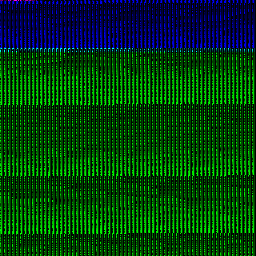

In [43]:
import zipfile
from pathlib import Path
from IPython.display import display

# Reuse the existing generator
generator_path = Path(
    "/content/drive/MyDrive/Malicious project work/byteplot_generator.py"
)

exec(generator_path.read_text(encoding="utf-8"), globals())

apk_path = "/content/com.iris.gallery_16.apk"

# Extract DEX bytes without executing the APK
with zipfile.ZipFile(apk_path, "r") as apk:
    dex_bytes = apk.read("classes.dex")

# Generate the existing experimental byteplot
byteplot_img = generate_precise_byteplot(
    dex_bytes,
    target_size=(256, 256)
)

print("DEX bytes:", f"{len(dex_bytes):,}")
print("Byteplot dimensions:", byteplot_img.size)
print("Image mode:", byteplot_img.mode)

display(byteplot_img)

In [44]:
import torch
from torchvision import transforms
from PIL import Image

# Temporary preprocessing assumption; verify against training code later.
preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

image_tensor = preprocess(byteplot_img).unsqueeze(0).to(device)

models_to_test = {
    "ResNet50": resnet_model,
    "MobileNetV3-Large": mobile_model
}

for model_name, model in models_to_test.items():
    model.eval()
    with torch.no_grad():
        logits = model(image_tensor)
        probabilities = torch.softmax(logits, dim=1)[0].cpu()

    predicted_index = int(probabilities.argmax())
    print(f"\n--- {model_name} ---")
    print("Experimental predicted class:", class_names[predicted_index])
    print("Experimental confidence:", f"{probabilities[predicted_index].item() * 100:.2f}%")
    print("Class probabilities:")
    for name, probability in zip(class_names, probabilities.tolist()):
        print(f"  {name}: {probability * 100:.2f}%")


--- ResNet50 ---
Experimental predicted class: riskware
Experimental confidence: 89.15%
Class probabilities:
  adware: 0.84%
  banking: 0.29%
  benign: 1.70%
  riskware: 89.15%
  sms: 8.02%

--- MobileNetV3-Large ---
Experimental predicted class: riskware
Experimental confidence: 68.53%
Class probabilities:
  adware: 0.28%
  banking: 15.43%
  benign: 7.65%
  riskware: 68.53%
  sms: 8.10%


In [45]:
import json
from pathlib import Path
import torch

results = {}

for model_name, model in {
    "ResNet50": resnet_model,
    "MobileNetV3-Large": mobile_model
}.items():
    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(image_tensor), dim=1)[0].cpu()

    results[model_name] = {
        "predicted_class": class_names[int(probs.argmax())],
        "experimental": True,
        "class_scores_percent": {
            name: round(float(prob) * 100, 2)
            for name, prob in zip(class_names, probs)
        }
    }

report_path = Path(
    "/content/drive/MyDrive/Malicious project work/"
    "apk_prediction_report.json"
)
report_path.parent.mkdir(parents=True, exist_ok=True)
report_path.write_text(json.dumps({
    "apk_filename": "com.iris.gallery_16.apk",
    "apk_size_bytes": 8314084,
    "models": results,
    "limitations": [
        "Experimental byteplot generation",
        "Training preprocessing not yet verified",
        "Prediction is not definitive malware proof"
    ]
}, indent=2), encoding="utf-8")

print("Report saved:", report_path)
print(report_path.read_text(encoding="utf-8"))


Report saved: /content/drive/MyDrive/Malicious project work/apk_prediction_report.json
{
  "apk_filename": "com.iris.gallery_16.apk",
  "apk_size_bytes": 8314084,
  "models": {
    "ResNet50": {
      "predicted_class": "riskware",
      "experimental": true,
      "class_scores_percent": {
        "adware": 0.84,
        "banking": 0.29,
        "benign": 1.7,
        "riskware": 89.15,
        "sms": 8.02
      }
    },
    "MobileNetV3-Large": {
      "predicted_class": "riskware",
      "experimental": true,
      "class_scores_percent": {
        "adware": 0.28,
        "banking": 15.43,
        "benign": 7.65,
        "riskware": 68.53,
        "sms": 8.1
      }
    }
  },
  "limitations": [
    "Experimental byteplot generation",
    "Training preprocessing not yet verified",
    "Prediction is not definitive malware proof"
  ]
}


In [46]:
# Check whether the existing Gemini agent and model outputs are available.

print("Gemini agent available:", "agent" in globals())
print("ResNet50 available:", "resnet_model" in globals())
print("MobileNetV3 available:", "mobile_model" in globals())
print("Byteplot available:", "byteplot_img" in globals())
print("Class names available:", "class_names" in globals())
print("Device:", device if "device" in globals() else "not set")

Gemini agent available: True
ResNet50 available: True
MobileNetV3 available: True
Byteplot available: True
Class names available: True
Device: cpu


In [48]:
import json
import time

report_prompt = f"""
Write a concise Android APK analysis report using only this evidence:
{json.dumps(evidence, indent=2)}

Include:
- APK filename
- ResNet50 and MobileNetV3-Large predictions and scores
- Their agreement on riskware
- Clear experimental-result warning
- LightGBM not run because the 316 required features are unavailable
- Unverified byteplot generation and image preprocessing
- Recommended next steps

Do not invent findings or call the APK definitively malicious.
"""

try:
    report_response = llm.invoke(report_prompt)
    gemini_report = report_response.content
    print(gemini_report)
except Exception as exc:
    print("Gemini report generation failed.")
    print("Error:", str(exc)[:700])
    print("\nThe model predictions remain available; no need to rerun inference.")

Gemini report generation failed.
Error: Error calling model 'gemini-3.8-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.8-flash\nPlease retry in 14h55m47.256291159s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url'

The model predictions remain available; no need to rerun inference.


In [49]:
import json
from pathlib import Path
from datetime import datetime, timezone

report = {
    "apk": {
        "filename": "com.iris.gallery_16.apk",
        "size_bytes": 8314084
    },
    "analysis_status": "experimental",
    "model_results": evidence["models"],
    "consensus": "riskware",
    "lightgbm": {
        "status": "not_run",
        "reason": (
            "The required 316 syscall/Binder frequency features "
            "have not been extracted from the uploaded APK."
        )
    },
    "limitations": [
        "Byteplot generation has not been verified against training data.",
        "Image normalization has not been verified against training preprocessing.",
        "Model scores are not proof of actual malware behavior.",
        "Gemini report generation is temporarily unavailable due to API quota."
    ],
    "report_generated_at_utc": datetime.now(timezone.utc).isoformat()
}

report_path = Path(
    "/content/drive/MyDrive/Malicious project work/"
    "apk_analysis_report.json"
)
report_path.write_text(json.dumps(report, indent=2), encoding="utf-8")

print("Report saved:", report_path)
print(json.dumps(report, indent=2))

Report saved: /content/drive/MyDrive/Malicious project work/apk_analysis_report.json
{
  "apk": {
    "filename": "com.iris.gallery_16.apk",
    "size_bytes": 8314084
  },
  "analysis_status": "experimental",
  "model_results": {
    "ResNet50": {
      "predicted_class": "riskware",
      "class_scores_percent": {
        "adware": 0.84,
        "banking": 0.29,
        "benign": 1.7,
        "riskware": 89.15,
        "sms": 8.02
      }
    },
    "MobileNetV3-Large": {
      "predicted_class": "riskware",
      "class_scores_percent": {
        "adware": 0.28,
        "banking": 15.43,
        "benign": 7.65,
        "riskware": 68.53,
        "sms": 8.1
      }
    }
  },
  "consensus": "riskware",
  "lightgbm": {
    "status": "not_run",
    "reason": "The required 316 syscall/Binder frequency features have not been extracted from the uploaded APK."
  },
  "limitations": [
    "Byteplot generation has not been verified against training data.",
    "Image normalization has not bee